# Step 2 — The frost-night calendar

Spec: `CLAUDE.md` §6 Step 2 and §5.4. **This is where K1 is first testable**, and the whole
study's sample size is whatever this step returns.

**Scope decision.** §5.4 asks for hourly and daily air temperature. This step pulls **daily
`DayAirTmpMin` only**, because a frost night is defined from the daily minimum. Hourly is needed
only once the frost nights are known — at satellite overpass time in Step 4, and across the night
in Step 7 — so it is pulled for those nights rather than for the whole window. Pulling hourly for
every night 2015–2025 would be roughly 1.2 million records, mostly warm nights nobody will look
at. Logged in `SPEC_CHANGELOG.md`.

**Stations.** Within 20 km of DWR 2023 almond acreage and nominally operating in the window
(§5.4, "in and adjacent to almond regions"). Each station is assigned to the stratum of its
nearest almond unit, not to its own county, because a station can serve almond acreage across a
county line.

**Denominator rule (§9).** Station-nights requested, returned, usable and frost are each reported
against what they were drawn from.

In [1]:
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

import common as C

plt.rcParams["mathtext.default"] = "regular"
C.FIGURES.mkdir(parents=True, exist_ok=True)

THRESHOLDS = [(0.0, "0 °C"), (-1.1, "−1.1 °C (30 °F)"), (-2.2, "−2.2 °C (28 °F)")]
SEVERE = {"I", "M", "S"}          # CIMIS "severe" flags — see the QC section below
SEASONS = list(range(2015, 2026))

daily = pd.read_csv(C.DERIVED / "02_cimis_daily_tmin.csv", parse_dates=["date"])
stations = pd.read_csv(C.DERIVED / "01_cimis_stations.csv")
print("source: data/derived/02_cimis_daily_tmin.csv (CIMIS day-air-tmp-min, metric)")
print(f"window: 1 Feb – 31 Mar, {SEASONS[0]}–{SEASONS[-1]}   thresholds: "
      f"{[t[1] for t in THRESHOLDS]}")
print(f"station-nights returned : {len(daily):,}")
print(f"stations with any data  : {daily.station.nunique()} of "
      f"{(stations.dist_to_almond_km <= 20).sum()} within 20 km of almond acreage")

source: data/derived/02_cimis_daily_tmin.csv (CIMIS day-air-tmp-min, metric)
window: 1 Feb – 31 Mar, 2015–2025   thresholds: ['0 °C', '−1.1 °C (30 °F)', '−2.2 °C (28 °F)']
station-nights returned : 31,746
stations with any data  : 63 of 93 within 20 km of almond acreage


In [2]:
# Assign each station to the stratum of its nearest almond unit.
units = gpd.read_file(C.DERIVED / "01_almond_fields_dwr2023.gpkg", engine="fiona")
units = units[units.is_unit == 1].to_crs(C.METRIC_CRS)
sg = gpd.GeoDataFrame(stations, geometry=[Point(x, y) for x, y in zip(stations.lon, stations.lat)],
                      crs="EPSG:4326").to_crs(C.METRIC_CRS)
cent = gpd.GeoDataFrame(units[["study_region"]].copy(), geometry=units.geometry.centroid,
                        crs=C.METRIC_CRS)
near = (gpd.sjoin_nearest(sg, cent, how="left", distance_col="d")
        .drop_duplicates(subset="StationNbr"))
daily["region"] = daily.station.map(dict(zip(near.StationNbr, near.study_region)))
daily["county"] = daily.station.map(dict(zip(near.StationNbr, near.County)))
daily["elev_m"] = daily.station.map(dict(zip(near.StationNbr, near.elev_m)))
daily["year"] = daily.date.dt.year
assert daily.region.notna().all(), "a station could not be assigned to a stratum"
print("stations per stratum:", daily.groupby("region").station.nunique().to_dict())
print("elevation of contributing stations (m): "
      f"median {daily.groupby('station').elev_m.first().median():.0f}, "
      f"range {daily.elev_m.min():.0f}–{daily.elev_m.max():.0f}")

stations per stratum: {'sac_valley': 19, 'sj_north': 18, 'sj_south': 26}
elevation of contributing stations (m): median 56, range -4–337


## 2a — QC flags, and the trap in them

Flag meanings are taken from DWR's published *Current Flags* document (CIMIS Resources), not
from assumption. It divides flags into two classes:

| class | flag | published meaning |
|---|---|---|
| **Severe** | `I` | "Data value has no meaning/ignore." |
| | `M` | "Missing." |
| | `S` | "Sensor is not in service or data is out of sensor threshold." |
| **Informative** | `R` | "Data is far out of historical limits." |
| | `Y` | "Data is moderately out of historical limits." |

**The trap: `Y` and `R` fire because the night was extreme.** They are historical-limit tests, so
on a record cold night a correct reading is flagged precisely because it is unusual. Dropping all
flagged data — the obvious, apparently conservative choice — would delete a large share of exactly
the nights this study exists to measure. The cell below quantifies it before any decision is made.

**Rule adopted:** severe flags (`I`, `M`, `S`) are dropped, because they carry no value at all.
`Y` and `R` are **kept and carried as a column**, and every frost-night count is reported with the
share of it that is flagged, so a reviewer can see the exposure.

In [3]:
print("QC flag distribution and what the flagged values look like:")
print(f"{'flag':<9}{'n':>7}{'class':>13}{'median':>9}{'min':>8}{'≤0 °C':>9}")
for flag, grp in sorted(daily.groupby(daily.qc), key=lambda kv: -len(kv[1])):
    v = grp.tmin_c.dropna()
    cls = "severe" if flag in SEVERE else ("informative" if flag != "(blank)" else "unflagged")
    if len(v) == 0:
        print(f"{flag:<9}{len(grp):>7}{cls:>13}{'—':>9}{'—':>8}{'no values':>12}")
    else:
        print(f"{flag:<9}{len(grp):>7}{cls:>13}{v.median():>9.1f}{v.min():>8.1f}"
              f"{100 * (v <= 0).mean():>8.1f}%")

ok = daily[~daily.qc.isin(SEVERE) & daily.tmin_c.notna()].copy()
print(f"\nusable station-nights: {len(ok):,} of {len(daily):,} returned "
      f"({100 * len(ok) / len(daily):.1f}%); {len(daily) - len(ok):,} dropped as severe/null")

print("\nWhat dropping the informative flags would cost:")
print(f"{'threshold':<20}{'frost nights':>14}{'flagged Y/R':>13}{'share':>8}{'if dropped':>12}")
for thr, lab in THRESHOLDS:
    f_all = ok[ok.tmin_c <= thr]
    f_yr = f_all[f_all.qc.isin({"Y", "R"})]
    print(f"{lab:<20}{len(f_all):>14,}{len(f_yr):>13,}{100 * len(f_yr) / len(f_all):>7.1f}%"
          f"{len(f_all) - len(f_yr):>12,}")
print("\nUnflagged nights are ≤0 °C 7.7% of the time; Y-flagged 44% and R-flagged 54%. The")
print("historical-limit tests are detecting the signal, not an error. Y and R are kept.")
ok["flagged"] = ok.qc.isin({"Y", "R"})

QC flag distribution and what the flagged values look like:
flag           n        class   median     min    ≤0 °C
(blank)    30038    unflagged      5.0    -6.7     7.7%
Y           1275  informative      1.5    -8.5    44.2%
M            246       severe        —       —   no values
S            141       severe        —       —   no values
R             46  informative     -0.9   -10.0    54.3%

usable station-nights: 31,359 of 31,746 returned (98.8%); 387 dropped as severe/null

What dropping the informative flags would cost:
threshold             frost nights  flagged Y/R   share  if dropped
0 °C                         2,910          588   20.2%       2,322
−1.1 °C (30 °F)              1,472          453   30.8%       1,019
−2.2 °C (28 °F)                687          317   46.1%         370

Unflagged nights are ≤0 °C 7.7% of the time; Y-flagged 44% and R-flagged 54%. The
historical-limit tests are detecting the signal, not an error. Y and R are kept.


## 2b — Frost nights per year and per stratum

In [4]:
obs_year = ok.groupby("year").size()
tables = {}
for thr, lab in THRESHOLDS:
    t = (ok[ok.tmin_c <= thr].pivot_table(index="year", columns="region", values="tmin_c",
                                          aggfunc="size").reindex(SEASONS).fillna(0).astype(int))
    for r in C.REGION_ORDER:
        if r not in t:
            t[r] = 0
    t = t[C.REGION_ORDER]
    t["TOTAL"] = t.sum(axis=1)
    t["observed"] = obs_year.reindex(SEASONS).fillna(0).astype(int)
    t["rate_%"] = (100 * t.TOTAL / t.observed).round(1)
    tables[lab] = t
    print(f"\nFROST NIGHTS at {lab}  (station-nights; 'observed' is the denominator)")
    print(t.to_string())

t0 = tables[THRESHOLDS[0][1]]
print(f"\nInterannual spread at 0 °C: {t0.TOTAL.min()} frost nights in {t0.TOTAL.idxmin()} to "
      f"{t0.TOTAL.max()} in {t0.TOTAL.idxmax()}, a factor of "
      f"{t0.TOTAL.max() / max(t0.TOTAL.min(), 1):.0f}.")
print(f"Median season: {t0.TOTAL.median():.0f} frost nights. The observing network is stable "
      f"({t0.observed.min():,}–{t0.observed.max():,} station-nights per season), so the")
print("spread is weather and not a changing denominator.")
print("\nBy month, at 0 °C:")
bym = ok[ok.tmin_c <= 0].groupby(ok.date.dt.month).size()
for m, n in bym.items():
    denom = (ok.date.dt.month == m).sum()
    print(f"   {'February' if m == 2 else 'March':<9} {n:>5,} frost nights of {denom:>6,} "
          f"observed ({100 * n / denom:.1f}%)")


FROST NIGHTS at 0 °C  (station-nights; 'observed' is the denominator)
region  sac_valley  sj_north  sj_south  TOTAL  observed  rate_%
year                                                           
2015            17        28        40     85      2966     2.9
2016            17        20       106    143      3102     4.6
2017            42        43       120    205      3220     6.4
2018           201       170       200    571      2915    19.6
2019            76        95       202    373      2898    12.9
2020            57        86       133    276      2922     9.4
2021            52        82        41    175      2829     6.2
2022           114       184       178    476      2724    17.5
2023           115       123       197    435      2553    17.0
2024            10         6        24     40      2640     1.5
2025            45        42        44    131      2590     5.1

FROST NIGHTS at −1.1 °C (30 °F)  (station-nights; 'observed' is the denominator)
region  sac_val

## 2c — The major events

A widespread valley freeze is far more useful than a scattered local one (§6 Step 2), so events
are ranked by **how many of the stations observing that night were at or below the threshold**,
with the share reported so a night with few stations reporting cannot masquerade as widespread.

In [5]:
obs_night = ok.groupby("date").station.nunique().rename("observing")
ev = (ok[ok.tmin_c <= 0].groupby("date")
      .agg(stations=("station", "nunique"), strata=("region", "nunique"),
           coldest=("tmin_c", "min"), median_tmin=("tmin_c", "median"),
           flagged=("flagged", "sum")).join(obs_night))
ev["share"] = (ev.stations / ev.observing).round(2)
ev = ev.sort_values(["stations", "coldest"], ascending=[False, True])
print(f"nights with at least one station at or below 0 °C: {len(ev):,} of "
      f"{ok.date.nunique():,} observed nights")
print(f"nights with at least 75% of observing stations at or below 0 °C: {(ev.share >= 0.75).sum()}")
print("\nTOP 15 WIDESPREAD FREEZE NIGHTS")
print(ev.head(15).to_string())

# Group consecutive widespread nights into events.
wide = ev[ev.share >= 0.75].sort_index()
grp = (wide.index.to_series().diff().dt.days.fillna(99) > 1).cumsum()
events = wide.groupby(grp).agg(start=("stations", lambda s: s.index.min()),
                               end=("stations", lambda s: s.index.max()),
                               nights=("stations", "size"), peak_stations=("stations", "max"),
                               coldest=("coldest", "min"))
events = events.sort_values(["nights", "coldest"], ascending=[False, True])
print(f"\nMULTI-NIGHT EVENTS (consecutive nights with ≥75% of stations at or below 0 °C): "
      f"{len(events)}")
print(events.to_string(index=False))

nights with at least one station at or below 0 °C: 333 of 652 observed nights
nights with at least 75% of observing stations at or below 0 °C: 15

TOP 15 WIDESPREAD FREEZE NIGHTS
            stations  strata  coldest  median_tmin  flagged  observing  share
date                                                                         
2018-02-20        49       3     -7.5        -3.00       32         50   0.98
2018-02-21        48       3     -6.0        -2.55       34         50   0.96
2018-02-24        47       3     -8.0        -3.20       45         49   0.96
2022-02-24        44       3     -6.4        -3.70       32         46   0.96
2018-02-22        41       3     -4.8        -2.00       16         50   0.82
2019-02-23        41       3     -4.4        -1.70       18         49   0.84
2022-02-25        39       3     -5.4        -2.60       21         46   0.85
2018-02-23        39       3     -5.0        -2.10       16         50   0.78
2019-02-06        39       3     -4.9    

In [6]:
print("COLDEST 12 STATION-NIGHTS")
cold = ok.nsmallest(12, "tmin_c")[["date", "station", "county", "region", "elev_m", "tmin_c", "qc"]]
print(cold.to_string(index=False))
print(f"\nThose 12 come from {cold.station.nunique()} distinct stations, so station extremes are "
      "concentrated.")
print("Per-station minima and frost counts are therefore reported as well as the event view:")
per = (ok.groupby("station").agg(county=("county", "first"), region=("region", "first"),
                                 elev_m=("elev_m", "first"), nights=("tmin_c", "size"),
                                 min_tmin=("tmin_c", "min"),
                                 frost_0=("tmin_c", lambda s: int((s <= 0).sum())))
       .sort_values("min_tmin"))
per["frost_rate_%"] = (100 * per.frost_0 / per.nights).round(1)
print(per.head(10).to_string())
print(f"\nfrost rate at 0 °C across the {len(per)} stations: median "
      f"{per['frost_rate_%'].median():.1f}%, range {per['frost_rate_%'].min():.1f}–"
      f"{per['frost_rate_%'].max():.1f}%")
print("A single station's minimum is a siting statement as much as a climate one; the event")
print("table above is the more reliable view of a widespread freeze.")

COLDEST 12 STATION-NIGHTS
      date  station          county   region   elev_m  tmin_c qc
2020-02-06      247    Contra Costa sj_north  -3.6576   -10.0  R
2017-02-13      203          Tulare sj_south  64.0080    -9.6  R
2017-02-01      203          Tulare sj_south  64.0080    -9.5  R
2017-02-10      203          Tulare sj_south  64.0080    -9.1  R
2023-02-06      247    Contra Costa sj_north  -3.6576    -8.5  Y
2017-02-08      203          Tulare sj_south  64.0080    -8.4  R
2018-02-24       92          Merced sj_north  22.8600    -8.0  R
2017-02-09      203          Tulare sj_south  64.0080    -8.0  R
2023-02-11      247    Contra Costa sj_north  -3.6576    -8.0  Y
2018-02-24      163 San Luis Obispo sj_south 269.7480    -7.6  Y
2018-02-20      148          Merced sj_north  60.9600    -7.5  Y
2017-02-05      203          Tulare sj_south  64.0080    -7.5  Y

Those 12 come from 5 distinct stations, so station extremes are concentrated.
Per-station minima and frost counts are therefore 

## 2d — K1

§4 K1: **fewer than 200 usable station-nights at or below the threshold and the study stops.**

In [7]:
print("K1 — usable frost station-nights against the 200 threshold")
print(f"{'threshold':<22}{'frost nights':>14}{'stations':>10}{'seasons':>9}   verdict")
k1 = {}
for thr, lab in THRESHOLDS:
    f = ok[ok.tmin_c <= thr]
    k1[lab] = len(f)
    print(f"{lab:<22}{len(f):>14,}{f.station.nunique():>10}{f.year.nunique():>9}   "
          f"{'PASS' if len(f) >= 200 else 'FAIL'} ({len(f) / 200:.0f}× the minimum)")
print(f"\nK1 PASSES at all three thresholds. The binding one is {THRESHOLDS[-1][1]} with "
      f"{k1[THRESHOLDS[-1][1]]:,} station-nights,")
print(f"{k1[THRESHOLDS[-1][1]] / 200:.1f}× the minimum, spread over "
      f"{ok[ok.tmin_c <= -2.2].station.nunique()} stations and "
      f"{ok[ok.tmin_c <= -2.2].year.nunique()} seasons.")
print("\nSample size is not the constraint on this study. What Step 3 tests is how many of these")
print("nights a satellite actually saw, which is a different and much smaller number.")

K1 — usable frost station-nights against the 200 threshold
threshold               frost nights  stations  seasons   verdict
0 °C                           2,910        61       11   PASS (15× the minimum)
−1.1 °C (30 °F)                1,472        58       11   PASS (7× the minimum)
−2.2 °C (28 °F)                  687        54       10   PASS (3× the minimum)

K1 PASSES at all three thresholds. The binding one is −2.2 °C (28 °F) with 687 station-nights,
3.4× the minimum, spread over 54 stations and 10 seasons.

Sample size is not the constraint on this study. What Step 3 tests is how many of these
nights a satellite actually saw, which is a different and much smaller number.


Figure 2: 31,359 usable station-nights, 2,910 at or below 0 °C, 63 stations, 11 seasons
saved figures/fig02_frost_nights.png


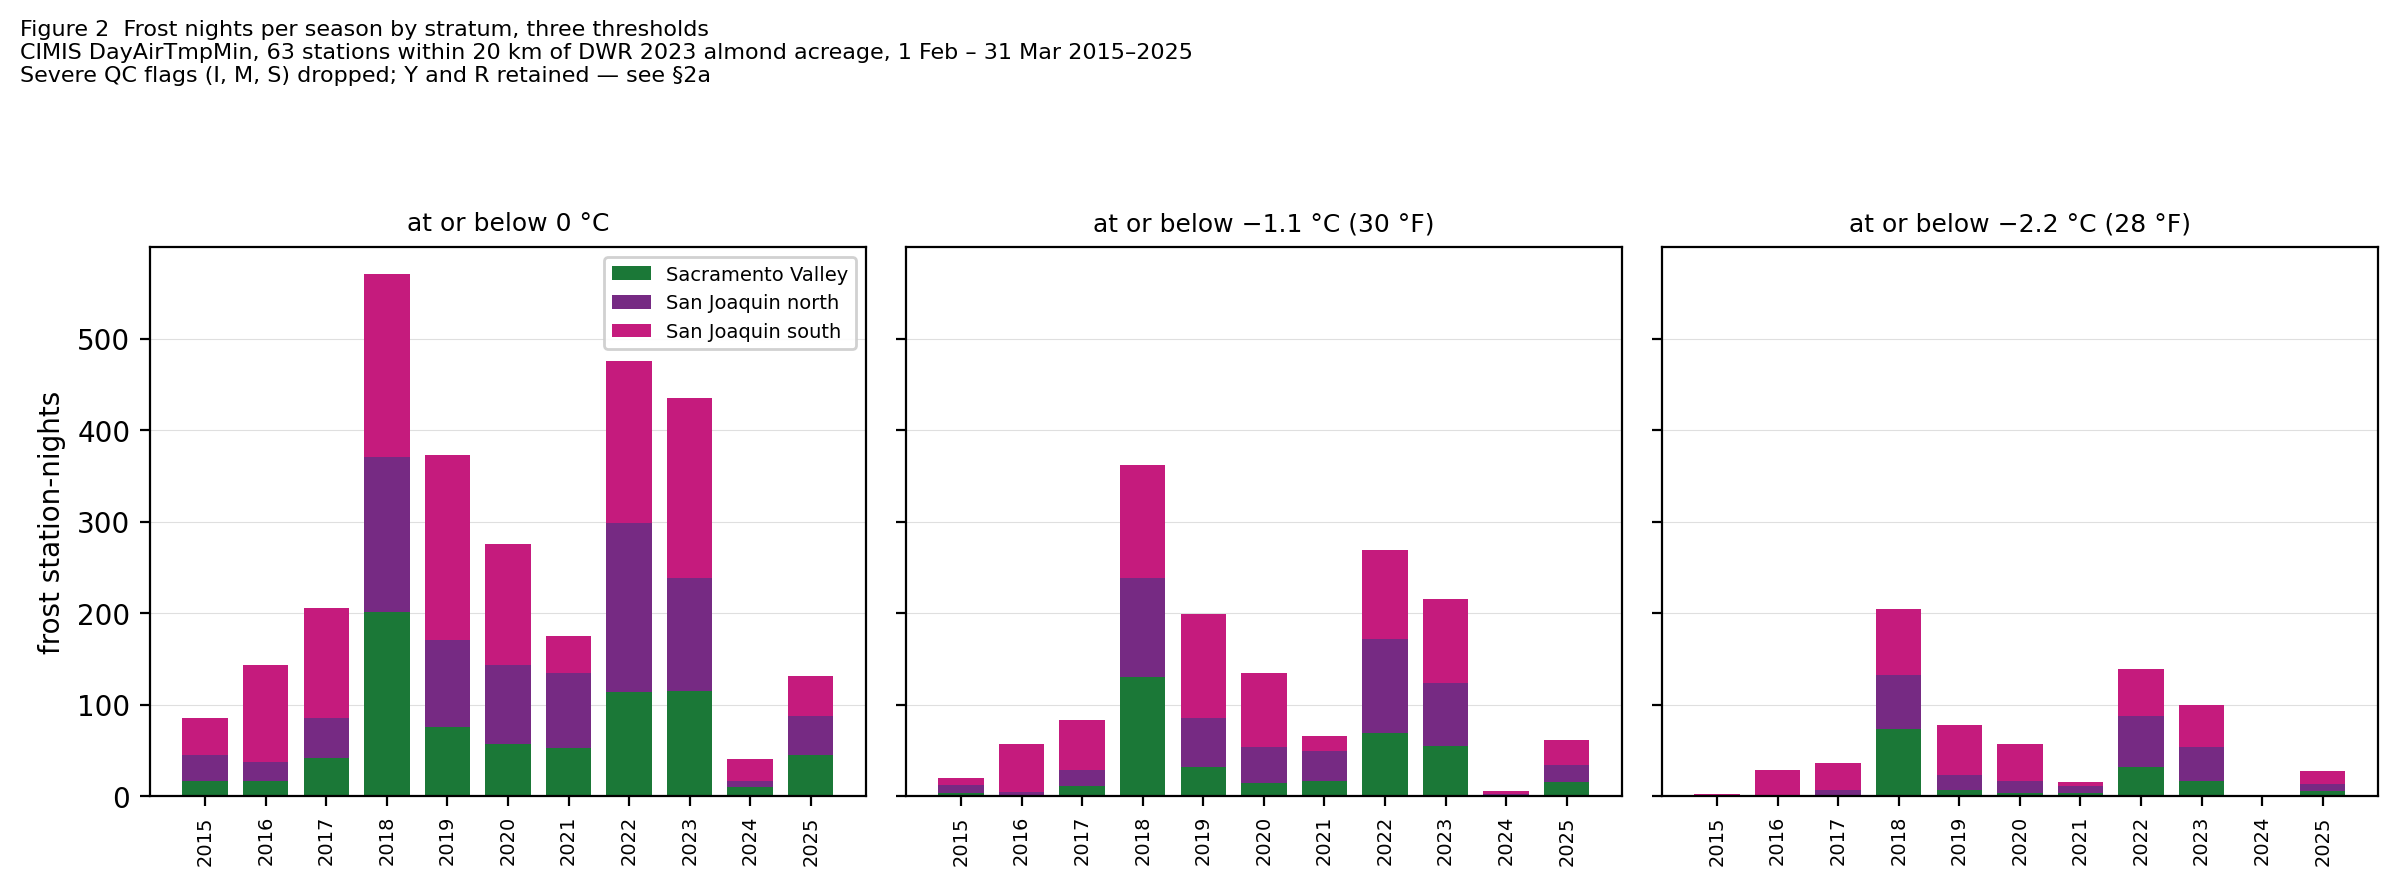

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), dpi=200, sharey=True)
colors = {"sac_valley": "#1b7837", "sj_north": "#762a83", "sj_south": "#c51b7d"}
for ax, (thr, lab) in zip(axes, THRESHOLDS):
    t = tables[lab]
    bottom = np.zeros(len(t))
    for r in C.REGION_ORDER:
        ax.bar(t.index, t[r], bottom=bottom, color=colors[r], label=C.REGION_LABELS[r], width=0.75)
        bottom += t[r].values
    ax.set_title(f"at or below {lab}", fontsize=9)
    ax.set_xticks(SEASONS)
    ax.set_xticklabels(SEASONS, rotation=90, fontsize=7)
    ax.grid(axis="y", lw=0.4, alpha=0.4)
    ax.set_axisbelow(True)
axes[0].set_ylabel("frost station-nights")
axes[0].legend(fontsize=7, framealpha=0.9)
fig.suptitle("Figure 2  Frost nights per season by stratum, three thresholds\n"
             "CIMIS DayAirTmpMin, 63 stations within 20 km of DWR 2023 almond acreage, "
             "1 Feb – 31 Mar 2015–2025\n"
             "Severe QC flags (I, M, S) dropped; Y and R retained — see §2a",
             fontsize=8, x=0.005, y=0.995, ha="left", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(C.FIGURES / "fig02_frost_nights.png", dpi=200, bbox_inches="tight")
print(f"Figure 2: {len(ok):,} usable station-nights, {len(ok[ok.tmin_c <= 0]):,} at or below 0 °C, "
      f"{daily.station.nunique()} stations, {len(SEASONS)} seasons")
print("saved figures/fig02_frost_nights.png")

In [9]:
ok.to_csv(C.DERIVED / "02_station_nights.csv", index=False)
ev.to_csv(C.DERIVED / "02_freeze_nights.csv")
events.to_csv(C.DERIVED / "02_major_events.csv", index=False)
for thr, lab in THRESHOLDS:
    tables[lab].to_csv(C.DERIVED / f"02_frost_by_year_{str(thr).replace('.', 'p')}.csv")

print("=" * 78)
print("STEP 2 CHECKPOINT SUMMARY — every figure with its denominator")
print("=" * 78)
print(f"stations within 20 km of almond acreage, operating   {daily.station.nunique():>8}")
print(f"station-nights requested (63 × 652)                  {63 * 652:>8,}")
print(f"station-nights returned                              {len(daily):>8,}   "
      f"({100 * len(daily) / (63 * 652):.1f}%)")
print(f"  dropped: severe QC flag or null value              {len(daily) - len(ok):>8,}")
print(f"  usable                                             {len(ok):>8,}   "
      f"({100 * len(ok) / len(daily):.1f}% of returned)")
for thr, lab in THRESHOLDS:
    n = len(ok[ok.tmin_c <= thr])
    print(f"frost station-nights at {lab:<21}      {n:>8,}   "
          f"({100 * n / len(ok):.1f}% of usable)")
print(f"nights with ≥75% of stations at or below 0 °C        {(ev.share >= 0.75).sum():>8}")
print(f"multi-night widespread events                        {len(events):>8}")
print(f"K1 (needs ≥200)                                      {'PASS':>8}")
print("\nwrote data/derived/: 02_station_nights.csv, 02_freeze_nights.csv, 02_major_events.csv,")
print("      02_frost_by_year_*.csv; figures/fig02_frost_nights.png")

STEP 2 CHECKPOINT SUMMARY — every figure with its denominator
stations within 20 km of almond acreage, operating         63
station-nights requested (63 × 652)                    41,076
station-nights returned                                31,746   (77.3%)
  dropped: severe QC flag or null value                   387
  usable                                               31,359   (98.8% of returned)
frost station-nights at 0 °C                          2,910   (9.3% of usable)
frost station-nights at −1.1 °C (30 °F)               1,472   (4.7% of usable)
frost station-nights at −2.2 °C (28 °F)                 687   (2.2% of usable)
nights with ≥75% of stations at or below 0 °C              15
multi-night widespread events                               8
K1 (needs ≥200)                                          PASS

wrote data/derived/: 02_station_nights.csv, 02_freeze_nights.csv, 02_major_events.csv,
      02_frost_by_year_*.csv; figures/fig02_frost_nights.png
